## Importando Librerias

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from joblib import load, dump
from sklearn.model_selection import train_test_split

## Ajustando umbral optimo del modelo

In [4]:
# Clase para cambiar umbral de modelo
class Modelo:
    def __init__(self, modelo):
        self.modelo = modelo
        self.umbral = 0.11730232425863889
        self.prediccion = []

    def predict(self, X):
        self.prediccion = []
        y_pred = self.modelo.predict_proba(X)[:,1]
        for i in y_pred:
            if i >= self.umbral:
                self.prediccion.append(1)
            else:
                self.prediccion.append(0)
        return self.prediccion

In [2]:
df = pd.read_csv("FeaturedData.csv") # Importando los datos
df.drop("Unnamed: 0", axis=1, inplace=True)
df.head(2)

,amount,trans_year,trans_month,age_groups,entertainment,food_dining,gas_transport,grocery_net,grocery_pos,health_fitness,...,"marketing, advertising, and sales",media and journalism,others,psychology and social work,retail and commerce,science and research,sports and physical health,surveying and planning,tourism and hospitality,fraud
0,4.97,2019,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,107.23,2019,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [4]:
# Creando sets de prueba y entrenamiento
Y = df["fraud"]
df.drop(labels=["fraud"], axis=1, inplace=True)
X = df
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, random_state=42)

In [5]:
bosque = load("RandomForestClassifierHyper.joblib")
modelo = Modelo(bosque)

## Explicaciones individuales Para Cada Categoría

In [6]:
# Uniendo los sets de prueba
data = pd.concat([x_test,y_test], axis=1)
data.head(2)

,amount,trans_year,trans_month,age_groups,entertainment,food_dining,gas_transport,grocery_net,grocery_pos,health_fitness,...,"marketing, advertising, and sales",media and journalism,others,psychology and social work,retail and commerce,science and research,sports and physical health,surveying and planning,tourism and hospitality,fraud
1045211,194.51,2020,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
547406,52.32,2019,7.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [7]:
# Creando muestra para explicar
test = pd.concat([data.query("fraud == 1").sample(100), data.query("fraud == 0").sample(100)], axis=0)
test["fraud"].value_counts()
test.drop(labels=["fraud"], axis=1, inplace=True)

In [18]:
# Obteniendo predicciones
y_pred = bosque.predict(test)

In [19]:
conteo = np.unique(y_pred, return_counts=True)
conteo

(array([0, 1], dtype=int64), array([136,  64], dtype=int64))

In [27]:
y_pred[105]

0

In [6]:
# Creando explicador de shap
explicador = shap.Explainer(modelo.modelo)
#shap_va = explicador(test)
#shap.initjs()

In [21]:
print("Tipo de explicador: ", type(shap_va))
print("Dimensiones del explicadore: ", shap_va.shape)

Tipo de explicador:  <class 'shap._explanation.Explanation'>
Dimensiones del explicadore:  (200, 43, 2)


### Fraude

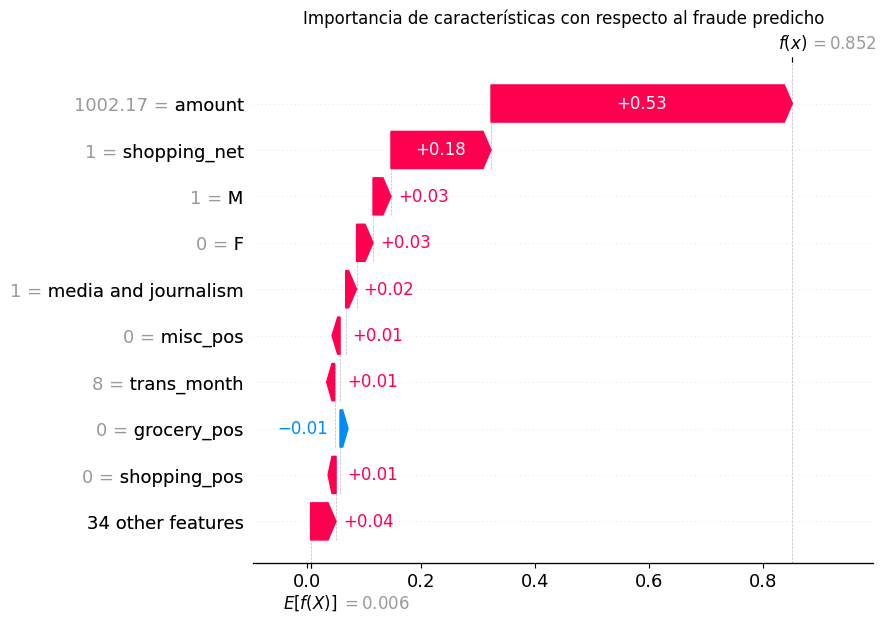

In [208]:
plt.title("Importancia de características con respecto al fraude predicho")
shap.plots.waterfall(shap_va[1][:,1], max_display=10)
plt.show()

In [25]:
shap.plots.force(shap_va[1][:,1])

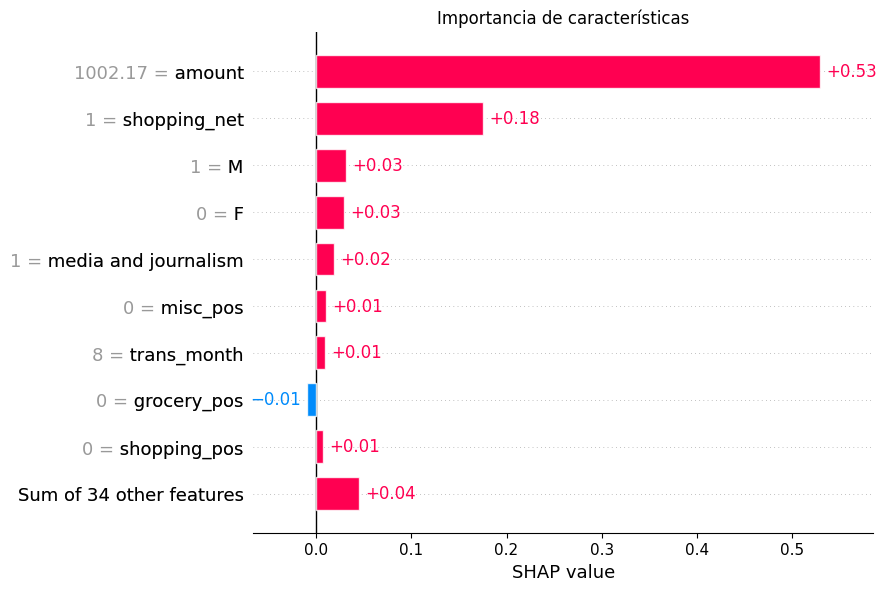

In [26]:
plt.title("Importancia de características")
shap.plots.bar(shap_va[1][:,1])
plt.show()

### No Fraude

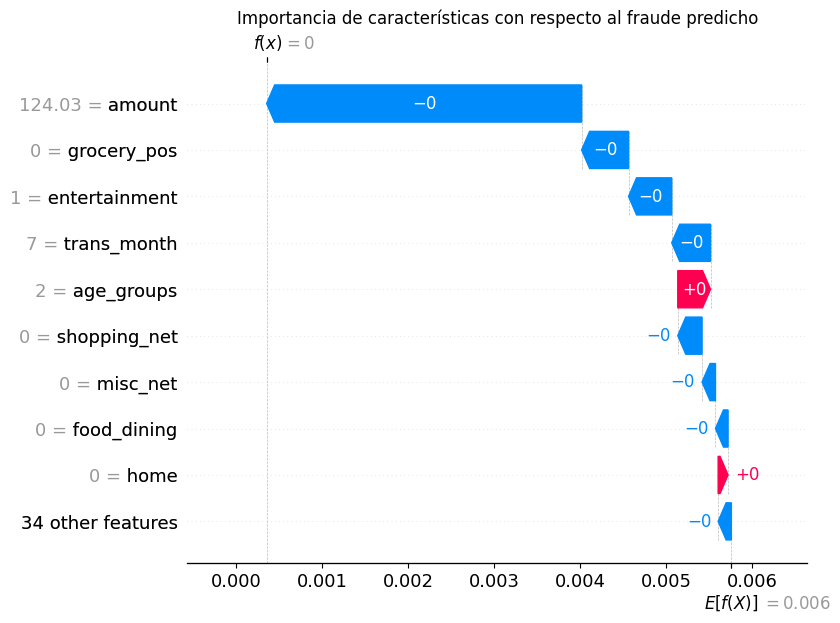

In [28]:
plt.title("Importancia de características con respecto al fraude predicho")
shap.plots.waterfall(shap_va[105][:,1], max_display=10)
plt.show()

In [29]:
shap.plots.force(shap_va[105][:,1])

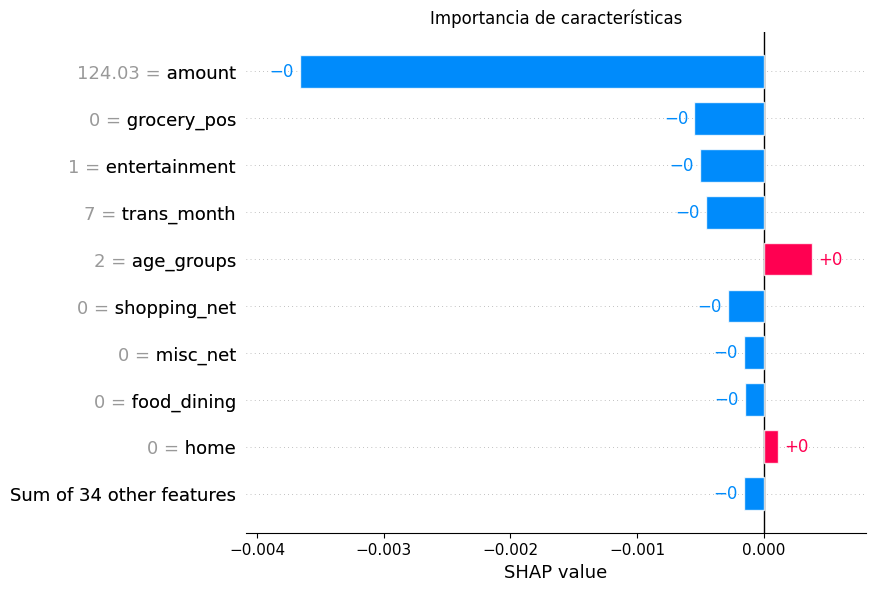

In [30]:
plt.title("Importancia de características")
shap.plots.bar(shap_va[105][:,1])
plt.show()

## Explicaciones Globales

In [90]:
shap_va.values.shape

(200, 43, 2)

In [176]:
fraud = [] 
for i in range(len(shap_va)):
    fraud.append(shap_va[i][:,1])

In [192]:
valores = []
for i in fraud:
    valores.append(i.values)
len(valores)

200

In [179]:
base = shap_va.base_values
len(base)

200

In [187]:
test_array = test.values
len(test_array)

200

In [188]:
col_nombres = shap_va.feature_names

In [189]:
fraud = shap.Explanation(values=valores,base_values=base,data=test_array, feature_names=col_nombres)

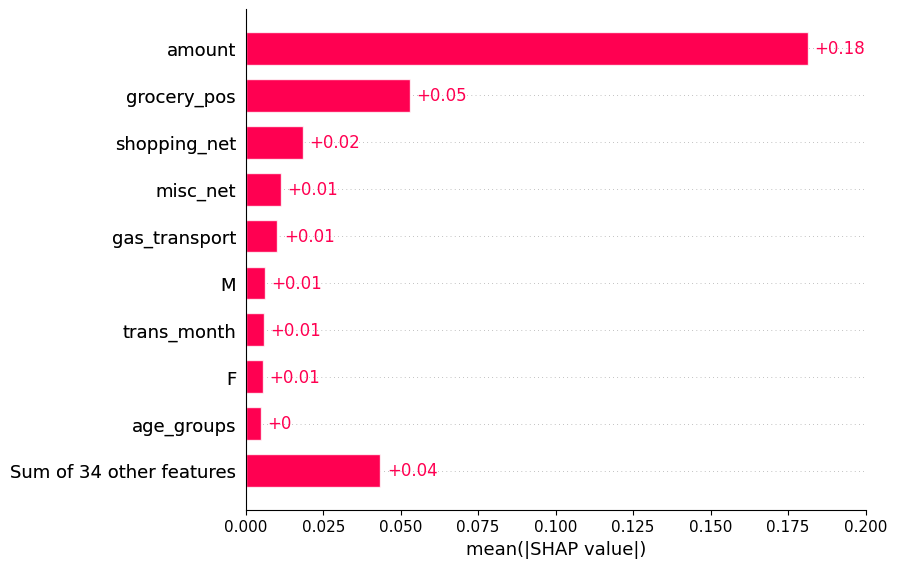

In [191]:
shap.plots.bar(fraud)

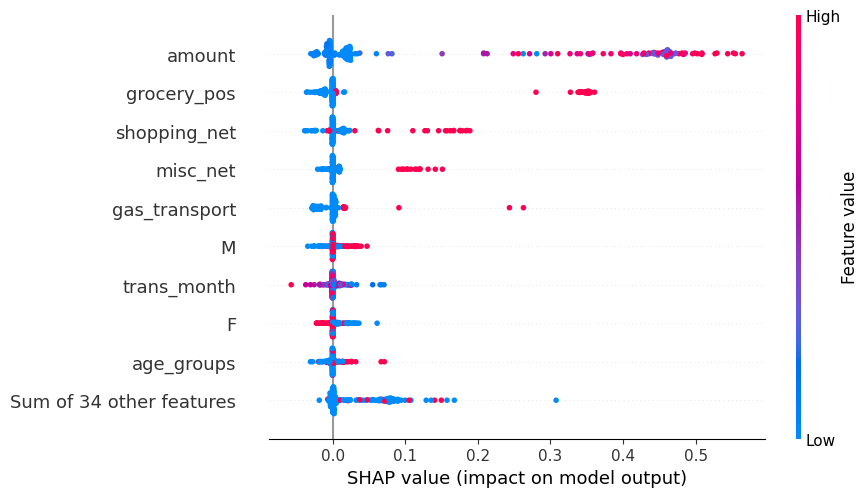

In [212]:
shap.plots.beeswarm(fraud)

## Exportando

In [10]:
dump(explicador, "shap.joblib")

['shap.joblib']